In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
print("All import done")

All import done


In [11]:
sns.set_theme(style="whitegrid")
print("Set theme done")
plt.rcParams['figure.figsize'] = (8,5)
print("Figure size: width:8, height:5 done")

Set theme done
Figure size: width:8, height:5 done


In [21]:
df=pd.read_csv("Project Assignment MLDA/student-por.csv", sep=',')
print(df)

    school sex  age address famsize Pstatus  Medu  Fedu      Mjob      Fjob  \
0       GP   F   18       U     GT3       A     4     4   at_home   teacher   
1       GP   F   17       U     GT3       T     1     1   at_home     other   
2       GP   F   15       U     LE3       T     1     1   at_home     other   
3       GP   F   15       U     GT3       T     4     2    health  services   
4       GP   F   16       U     GT3       T     3     3     other     other   
..     ...  ..  ...     ...     ...     ...   ...   ...       ...       ...   
644     MS   F   19       R     GT3       T     2     3  services     other   
645     MS   F   18       U     LE3       T     3     1   teacher  services   
646     MS   F   18       U     GT3       T     1     1     other     other   
647     MS   M   17       U     LE3       T     3     1  services  services   
648     MS   M   18       R     LE3       T     3     2  services     other   

     ... famrel freetime  goout  Dalc  Walc health 

In [19]:
selected_features = ['age','studytime', 'failures', 'absences', 'schoolsup', 'famsup', 'Medu', 'Fedu',
'internet', 'higher', 'goout', 'health','traveltime', 'freetime']
print("Done")

Done


In [22]:
df['Pass'] = (df['G3'] >= 10).astype(int)
print("Done")

Done


In [26]:
X=df[selected_features].copy()
y=df['Pass']
print(X)

     age  studytime  failures  absences schoolsup famsup  Medu  Fedu internet  \
0     18          2         0         4       yes     no     4     4       no   
1     17          2         0         2        no    yes     1     1      yes   
2     15          2         0         6       yes     no     1     1      yes   
3     15          3         0         0        no    yes     4     2      yes   
4     16          2         0         0        no    yes     3     3       no   
..   ...        ...       ...       ...       ...    ...   ...   ...      ...   
644   19          3         1         4        no     no     2     3      yes   
645   18          2         0         4        no    yes     3     1      yes   
646   18          2         0         6        no     no     1     1       no   
647   17          1         0         6        no     no     3     1      yes   
648   18          1         0         4        no     no     3     2      yes   

    higher  goout  health  

In [29]:
#X-shape is (total sample,selected_features)'
print("Initial X Shape:", X.shape)
print("Target Distribution:\n", y.value_counts(normalize=True))

X-shape is (total sample,selected_features)
Initial X Shape: (649, 14)
Target Distribution:
 Pass
1    0.845917
0    0.154083
Name: proportion, dtype: float64


In [30]:
print("\nMissing values in selected features:\n", X.isnull().sum())
print("Duplicate rows across features:", X.duplicated().sum())


Missing values in selected features:
 age           0
studytime     0
failures      0
absences      0
schoolsup     0
famsup        0
Medu          0
Fedu          0
internet      0
higher        0
goout         0
health        0
traveltime    0
freetime      0
dtype: int64
Duplicate rows across features: 0


C:\Users\HP VICTUS\AppData\Local\Temp\ipykernel_20084\656088550.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Pass', data=df, palette='pastel')


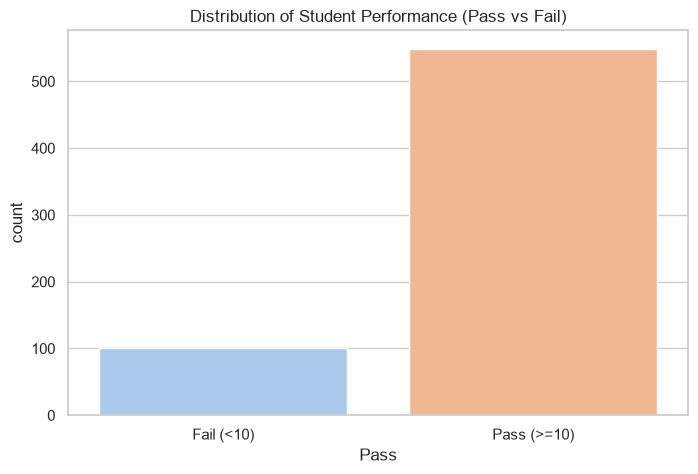

In [34]:
#EDA
plt.figure(figsize=(6, 4))
sns.countplot(x='Pass', data=df, palette='pastel')
plt.title('Distribution of Student Performance (Pass vs Fail)')
plt.xticks([0, 1], ['Fail (<10)', 'Pass (>=10)'])
plt.show()

In [33]:
numeric_cols = [
    'age', 'studytime', 'failures', 'absences', 
    'Medu', 'Fedu', 'goout', 'health', 
    'traveltime', 'freetime'
]
print("Done")

Done


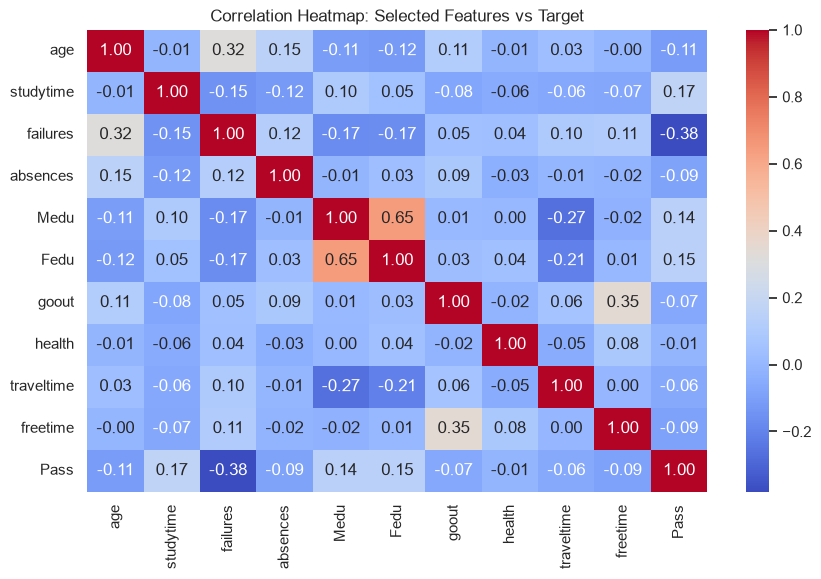

In [35]:
plt.figure(figsize=(10, 6))
sns.heatmap(df[numeric_cols + ['Pass']].corr(), annot=True, fmt=".2f", cmap='coolwarm', cbar=True)
plt.title('Correlation Heatmap: Selected Features vs Target')
plt.show()

In [37]:
# 5. Data Encoding
# Map binary categorical columns from ('yes'/'no') to (1/0)
binary_map = {'yes': 1, 'no': 0}
categorical_cols = ['schoolsup', 'famsup', 'internet', 'higher']

for col in categorical_cols:
    X[col] = X[col].map(binary_map)

In [45]:
%pip install scikit-learn

   ---------------------------------------- 0.0/8.3 MB ? eta -:--:--
   -------- ------------------------------- 1.8/8.3 MB 10.1 MB/s eta 0:00:01
   -------------------- ------------------- 4.2/8.3 MB 11.4 MB/s eta 0:00:01
   ------------------------- -------------- 5.2/8.3 MB 8.8 MB/s eta 0:00:01
   ----------------------------------- ---- 7.3/8.3 MB 9.2 MB/s eta 0:00:01
   ---------------------------------------- 8.3/8.3 MB 9.3 MB/s  0:00:00
   ---------------------------------------- 0.0/36.7 MB ? eta -:--:--
   -- ------------------------------------- 2.6/36.7 MB 13.7 MB/s eta 0:00:03
   ----- ---------------------------------- 5.2/36.7 MB 13.9 MB/s eta 0:00:03
   ------- -------------------------------- 6.8/36.7 MB 13.5 MB/s eta 0:00:03
   ------- -------------------------------- 6.8/36.7 MB 13.5 MB/s eta 0:00:03
   -------- ------------------------------- 7.3/36.7 MB 7.5 MB/s eta 0:00:04
   ----------- ---------------------------- 10.2/36.7 MB 8.4 MB/s eta 0:00:04
   ------------


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [46]:
from sklearn.preprocessing import StandardScaler
print("Import")

Import


In [47]:
# 6. Feature Scaling
# Scale numeric columns using StandardScaler so models like Logistic Regression converge properly

scaler = StandardScaler()
X[numeric_cols] = scaler.fit_transform(X[numeric_cols])

print("\nFinal Processed Feature Matrix (X):")
print(X.info())
print("\nFirst 3 rows of processed features ready for Member 3:")
display(X.head(3))


Final Processed Feature Matrix (X):
<class 'pandas.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 14 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   age         649 non-null    float64
 1   studytime   649 non-null    float64
 2   failures    649 non-null    float64
 3   absences    649 non-null    float64
 4   schoolsup   649 non-null    int64  
 5   famsup      649 non-null    int64  
 6   Medu        649 non-null    float64
 7   Fedu        649 non-null    float64
 8   internet    649 non-null    int64  
 9   higher      649 non-null    int64  
 10  goout       649 non-null    float64
 11  health      649 non-null    float64
 12  traveltime  649 non-null    float64
 13  freetime    649 non-null    float64
dtypes: float64(10), int64(4)
memory usage: 71.1 KB
None

First 3 rows of processed features ready for Member 3:


,age,studytime,failures,absences,schoolsup,famsup,Medu,Fedu,internet,higher,goout,health,traveltime,freetime
0,1.031695,0.083653,-0.374305,0.073433,1,0,1.310216,1.540715,0,1,0.693785,-0.371042,0.576718,-0.171647
1,0.210137,0.083653,-0.374305,-0.357863,0,1,-1.336039,-1.188832,1,1,-0.157380,-0.371042,-0.760032,-0.171647
2,-1.432980,0.083653,-0.374305,0.504730,1,0,-1.336039,-1.188832,1,1,-1.008546,-0.371042,-0.760032,-0.171647
